---
title: Manage a quantum-centric supercomputing workflow with qcsc-prefect
description: Run a sample-based quantum diagonalization workflow across a QPU and Slurm with qcsc-prefect, and resume it after failures.
---

{/* cspell:ignore sbatch Miyabi Fugaku LAPACK diagonalizer DIIS sacct ckpt SABRE IQP Kumar Shirakawa Wakizaka Hamamura Sato DMRG ROQUO */}

# Manage a quantum-centric supercomputing workflow with qcsc-prefect

*Usage estimate: 30 seconds of QPU time on an IBM Quantum&reg; Heron r2 processor. This estimate excludes queue time and classical processing. Your runtime might vary.*

## Learning outcomes

- Trace a quantum-centric supercomputing (QCSC) workflow in Prefect Cloud, with one Prefect
   task per Qiskit pattern stage.
- Configure the parameters of the workflow by role, with run parameters in the Prefect Cloud
   run form, and the high-performance computing (HPC) and quantum processing unit (QPU)
   settings in Prefect blocks.
- Resume a failed run without repeating its QPU job, and reuse the samples of one run in a
   new run.

## Prerequisites

- [Set up qcsc-prefect on a Slurm cluster](/docs/guides/qcsc-prefect-setup), which prepares the Slurm login node, the
  Python environments, and the IBM Quantum credentials that this tutorial uses.
- [Sample-based quantum diagonalization of a chemistry Hamiltonian](/docs/tutorials/sample-based-quantum-diagonalization), which
  explains the algorithm that this tutorial runs.

## Background

A QCSC workflow runs a QPU and an HPC system as one
machine. Such a workflow is hard to run manually. It spans several schedulers and services,
it has many parameters, and a failure in a late stage can waste the results of the earlier
ones. [qcsc-prefect](https://github.com/qiskit-community/qcsc-prefect) runs QCSC workflows on [Prefect](https://www.prefect.io/) and keeps them traceable, configurable, and resumable.

This tutorial demonstrates these features with sample-based quantum diagonalization (SQD) of the N$_2$ molecule. The [Quantum Resource Management Interface (QRMI)](https://github.com/qiskit-community/qrmi) samples the circuit inside a [Slurm](https://slurm.schedmd.com/) job, and the
[Fulqrum](https://github.com/Qiskit/qiskit-fulqrum) eigensolver diagonalizes the sampled
subspaces as Slurm jobs, all from one [Prefect Cloud](https://www.prefect.io/cloud) deployment.

qcsc-prefect also runs large QCSC workloads. A study of iron-sulfur clusters extended the
qcsc-prefect SQD workflow and ran it with 36 orbitals (72 qubits) and subspace dimensions up to
$3 \times 10^{10}$, on the Fugaku, Miyabi, and ROQUO supercomputers [\[2\]](#references).

### The challenge of QCSC workflows

The SQD workflow in this tutorial is typical of QCSC workloads in the following ways.

- **It spans several resources, which makes it hard to trace.** A Slurm job holds the QPU
  and samples a circuit. Then several Slurm jobs diagonalize subspaces on the compute nodes,
  round after round.
- **It has many parameters, at different levels, which makes it hard to configure.** Some parameters describe the science (the molecule,
  the subspace dimension), some describe the circuit and its compilation, and some describe
  the cluster (partition, walltime, and the path of the solver executable). Credentials must
  stay out of all of them.
- **It is long and can fail anywhere, which makes it hard to resume.** A solver job can hit its walltime, a node can fail,
  or the QPU queue can be long. Without care, a failure in the last stage requires sampling on
  the QPU again.

qcsc-prefect addresses each of these points with a traceable workflow, configurable
parameters, and resumable execution.

### Traceable workflow

A Prefect *flow* is a Python function made of *tasks*. qcsc-prefect makes each stage of a
[Qiskit pattern](/docs/guides/intro-to-patterns) (**Map**, **Optimize**, **Execute**, and **Postprocess**) one task. For every run, Prefect Cloud shows the following information:

- The task graph, with an arrow wherever a task passes its result to another task.
- The state, inputs, logs, and duration of each task, filterable by stage tag (`map`, `optimize`, `execute`, and `post-process`).
- The *artifacts*, which are tables and links that tasks publish, such as where the samples
  came from or the energy of each subspace.

The workflow host only submits and monitors work. The compute-intensive work runs as Slurm jobs, as illustrated in the following image.

![Runs, logs, and artifacts run on Prefect Cloud. The workflow host polls it for runs and reports states and logs. The served deployment runs on the workflow host. It submits and monitors the Slurm jobs. The QRMI worker, which compiles and samples, runs on the Slurm job (`sbatch --qpu`), which is submitted by the workflow host and communicates with the IBM Quantum QPU. One Fulqrum job per subspace runs on Slurm jobs (`sbatch`), which are submitted by the workflow host.](/docs/images/tutorials/qcsc-prefect/where-work-runs.svg 'What runs where')

### Configurable parameters

qcsc-prefect keeps each kind of setting in its own layer.

| Layer | Examples | Changes | Where it lives |
|---|---|---|---|
| Run parameters | Molecule, shots, subspace dimension | Every run | The Prefect Cloud run form |
| Blocks | Partition, walltime, threads, executable paths, QPU resource | Per cluster | Prefect blocks, created one time |
| Credentials | IBM Quantum API key and CRN | Rarely | QRMI and SPANK on the cluster, set up when following the setup guide |

The run form groups the run parameters by stage, so a run is described by what you study,
not by how the cluster works. The blocks describe each job in three layers.

- A `CommandBlock` specifies *what* runs, which is the executable and its default arguments.
- An `ExecutionProfileBlock` specifies *how* it runs, with the nodes, threads, walltime, launcher, modules, and environment.
- An `HPCProfileBlock` specifies *where* it runs, with the scheduler, partition, account, and the path of each executable on that system.

The flow loads blocks by name when it runs, so the flow and its run parameters stay the
same when you change a block.

### Resumable execution

The results from the first three stages' tasks are persistent, so Prefect stores them with the
flow run. If a later task fails, **Retry** on the flow run reuses the stored results and runs
only what failed, as shown in the following image.

![If a run fails, then you raise the walltime in the block, only the last stage has to be repeated. The results from the first stages are reused.](/docs/images/tutorials/qcsc-prefect/retry-failed-run.svg 'Retry a failed run')

A new run can also start from earlier samples. The Execute stage records where its samples
are, and a run that points to them loads them instead of sampling.

### SQD at a glance

SQD samples bitstrings from a local unitary cluster Jastrow (LUCJ) circuit built from coupled cluster singles and doubles (CCSD) amplitudes, fixes the
bitstrings that noise has corrupted (*configuration recovery*), and diagonalizes the
Hamiltonian in subspaces spanned by the sampled configurations [\[1\]](#references). The
[SQD tutorial](/docs/tutorials/sample-based-quantum-diagonalization) explains the algorithm. In qcsc-prefect, SQD is the
flow `sqd`, which has the following task graph.

| Stage | Task | Input from another task |
|---|---|---|
| Map | `compute_molecular_integrals` | None |
| Optimize | `get_lucj_params` | Integrals from Map |
| Execute | `quantum_sampling`, with `build_lucj_circuit` inside it | LUCJ parameters from Optimize |
| Postprocess | `sqd_loop` | Integrals from Map, and samples from Execute |

When a run reuses samples, `load_qrmi_result` or `load_runtime_job` replaces `get_lucj_params`
and `quantum_sampling`. In random mode, there is no Optimize or Execute task, and Map feeds the
`sqd_loop` task directly.

The example is N$_2$ at a bond length of 1.1 $\AA$ in the 6-31G basis, with the two 1s core orbitals frozen. This gives 16 spatial orbitals with five $\alpha$ and five $\beta$ electrons, which is a 32-qubit circuit.

### What comes next

- [Requirements](#requirements) installs the workflow and the solver, creates the blocks of the workflow, and deploys it.
- [Qiskit Pattern in QCSC-Prefect step by step](#qiskit-pattern-in-qcsc-prefect-step-by-step) goes through the four stages one at a time. Each step computes the stage in this
  notebook, then shows how you trace it, configure it, and resume it with qcsc-prefect.
- [Run the full workflow](#run-the-full-workflow) runs the whole workflow from Prefect Cloud in one click and reads its results.
- [Optional: resume and reuse the workflow](#optional-resume-and-reuse-the-workflow) retries a failed run and reuses its samples.

## Requirements

To run the code cells of this notebook, install the following packages in the notebook's
kernel.

*   Qiskit SDK v2.0 or later, with [visualization](/docs/api/qiskit/visualization) support.
*   Qiskit Runtime v0.40 or later (`pip install qiskit-ibm-runtime`).
*   SQD Qiskit addon v0.14 or later (`pip install qiskit-addon-sqd`).
*   ffsim v0.0.75 or later (`pip install ffsim`).
*   Fulqrum v1.0 or later (see the [Fulqrum installation guide](https://qiskit.github.io/qiskit-fulqrum/install.html)).

The execute step of the notebook samples with Qiskit Runtime, so it needs an IBM Quantum
account saved on the computer that runs the notebook, as described in
[Save your login credentials](/docs/guides/save-credentials).

<Admonition type="note">

The qcsc-prefect workflow itself runs on a Slurm-managed cluster, not in this notebook. Before
you run it, complete [Set up qcsc-prefect on a Slurm cluster](/docs/guides/qcsc-prefect-setup),
which provides the following items.

- The qcsc-prefect checkout at `$QCSC_PREFECT` (`~/qcsc-prefect`), on storage that the
  compute nodes share.
- A Python environment, `~/venv/prefect`, with the qcsc-prefect packages on the Slurm
  login node, which serves as the workflow host.
- Prefect Cloud login on the workflow host.
- A work directory at `$QCSC_WORK_DIR` (`/shared/work/sqd`), shared by the workflow host and
  the compute nodes.
- The IBM Quantum credentials stored with `qcsc-qrmi login`, and the `qrmi-runtime` block, on
  a cluster where the administrator installed QRMI and its SPANK plugin.
- On the compute nodes, a Python environment for the QRMI worker, `~/venv/sqd-node`, with
  QRMI, its `task_runner`, and `qcsc-prefect-qiskit`.

</Admonition>

Then install the SQD workflow, build the solver, create the Prefect blocks of the workflow,
and deploy it. Run the following steps one time. Each step names the node that it runs on.

### Install the SQD workflow on the workflow host

Set the variables of the setup guide, activate `~/venv/prefect`, and install the SQD
workflow and the Fulqrum integration into it.

```bash
# Run in a terminal on the workflow host.
# Optional if your ~/.bashrc sets the two variables
export QCSC_PREFECT="$HOME/qcsc-prefect"
export QCSC_WORK_DIR=/shared/work/sqd

source ~/venv/prefect/bin/activate
cd "$QCSC_PREFECT"
uv pip install --no-deps -e packages/qcsc-prefect-fulqrum
uv pip install -e algorithms/qcsc_workflow_utility
uv pip install -e algorithms/open_loop/sqd
which sqd-create-blocks sqd-deploy
```

### Install the Fulqrum solver on a compute node

Open a shell on a compute node. `srun` passes the variables of the workflow host shell to
the compute node.

```bash
# Run in a terminal on the workflow host.
srun -N1 --pty bash
```

The QRMI worker compiles the circuit on the compute node with the SQD compilation hook.
Add the hook to `~/venv/sqd-node`, the compute-node environment of the setup guide, and
check the imports. The hook imports only Qiskit, so it needs no dependencies. The `python`
command prints nothing when the imports succeed.

```bash
# Run in the shell on the compute node.
source ~/venv/sqd-node/bin/activate
cd "$QCSC_PREFECT"
uv pip install --no-deps -e algorithms/open_loop/sqd
python -c "import qrmi, qcsc_prefect.integrations.qiskit.qrmi.worker, sqd_common.transpile"
```

Build Fulqrum into its own virtual environment, `packages/qcsc-prefect-fulqrum/native/fulqrum`,
together with `qcsc-fulqrum-solve`. The build needs a C++ compiler with OpenMP, and the
environment does not need Prefect. `FULQRUM_WITH_PRIMME=1` also builds the PRIMME
eigensolver, which needs a C compiler, Python headers, `pkg-config`, and a BLAS and LAPACK
library with a `.pc` file.

```bash
# Run in the shell on the compute node.
cd "$QCSC_PREFECT"
FULQRUM_WITH_PRIMME=1 bash packages/qcsc-prefect-fulqrum/native/build_fulqrum.sh
realpath packages/qcsc-prefect-fulqrum/native/fulqrum/bin/qcsc-fulqrum-solve
exit
```

Record the path of `qcsc-fulqrum-solve`, because the solver blocks point to it. The `exit`
command returns to the workflow host. See
[Fulqrum integration](https://qiskit-community.github.io/qcsc-prefect/howto/howto_use_fulqrum_prefect/) for the build options.

### Configure and create the Prefect blocks on the workflow host

Copy the example configuration.

```bash
# Run in a terminal on the workflow host.
cd "$QCSC_PREFECT"
cp algorithms/open_loop/sqd/sqd_blocks.example.toml \
   algorithms/open_loop/sqd/sqd_blocks.toml
```

`sqd_blocks.toml` keeps the settings that you edit at the top. Edit them as in the following
table.

| Parameter | Example | Description |
|---|---|---|
| `python_executable` | `"~/venv/sqd-node/bin/python"` | The Python of the compute-node environment, with the hook from [Install the Fulqrum solver on a compute node](#install-the-fulqrum-solver-on-a-compute-node) |
| `profile` | `"slurm"` | System profile, which is `slurm`, `miyabi`, `fugaku`, or a path to your own |
| `solver` | `"fulqrum"` | Subspace diagonalizer, which is `fulqrum`, `sbd`, or `dice` |
| `queue` | `"normal"` | Slurm partition for the solver jobs |
| `project` | `"my-account"` | Optional Slurm account (`#SBATCH --account`) |
| `work_dir` | `"/shared/work/sqd"` | The value of `QCSC_WORK_DIR`, which holds the job directories and is shared by the host and the nodes |
| `fulqrum_executable` | `"~/qcsc-prefect/packages/qcsc-prefect-fulqrum/native/fulqrum/bin/qcsc-fulqrum-solve"` | The path from [Install the Fulqrum solver on a compute node](#install-the-fulqrum-solver-on-a-compute-node) |
| `eigensolver` | `"primme"` | The Fulqrum sparse solver, which is `primme` (built in [Install the Fulqrum solver on a compute node](#install-the-fulqrum-solver-on-a-compute-node)) or `scipy` |

`sqd_blocks.toml` does not expand environment variables, so write the paths out. The `~`
character works. `python_executable` is a top-level key. Keep every top-level setting before
the first table header. The `[qrmi]` table later in the file is active by default and needs no
change, because the instance and the QPU come from the `qrmi-runtime` block that
`qcsc-qrmi login` saved. Set
its `resource` only to override the block's backend. The credentials stay in
`qrmi_config.json`, so the file holds no secret.

The **profile** holds the scheduler and resource settings of your system, such as the HPC
target, nodes, threads, walltime, and modules, and the walltime and threads of the QRMI job.
The `slurm` profile suits a generic Slurm cluster, and any key that you set in your file
overrides it. The commented `[sqd_advanced]` table sets the CCSD restarts, reset mitigation, and the
transpiler of the `sqd-advanced-settings` block. Rarely changed settings, such as block
names and timeouts, are in a commented `[advanced]` table at the end of the file, and the solver tuning is commented in the
solver's table. See
[Size the SQD diagonalization for your HPC resources](https://qiskit-community.github.io/qcsc-prefect/tutorials/configure_sqd_solver_resources/) to choose the nodes,
ranks, and threads of the solver jobs for your system.

The `slurm` profile gives the QRMI sampler job and each Fulqrum solver job a walltime of 12
hours (`#SBATCH --time`), which leaves room for a long QPU queue and a large subspace. Slurm
stops a job at its walltime. The flow waits up to 13 hours (`timeout_seconds = 46800`) for each
job. To change the walltime, set `walltime` at the top of your file for the solver jobs, or in
the `[qrmi]` table for the QRMI job, for example `walltime = "02:00:00"`. A shorter walltime
can start sooner on a busy cluster.

Then create the blocks.

```bash
# Run in a terminal on the workflow host.
sqd-create-blocks --config algorithms/open_loop/sqd/sqd_blocks.toml
```

The command saves two sets of the three block layers. One set is for the solver jobs, and the
other is for the QRMI sampler job, which requests the QPU. It adds the Slurm settings of the QRMI set to
the `qrmi-runtime` block, and keeps the instance and backend chosen there. The
`sqd-fulqrum-solver` block, a `FulqrumSolverJob`, wraps the solver set and holds the
eigensolver settings (PRIMME in this tutorial). The flow calls it one time for each subspace. The
`sqd-advanced-settings` block records `fulqrum_solver_job/sqd-fulqrum-solver` as the
**Solver Block** of every run, with CCSD restarts, reset mitigation, and the transpiler
settings. Add `--dry-run` to print the resolved settings without saving anything. `prefect block ls` and the **Blocks** page of Prefect Cloud list them, as in the following
image.

> **Image placeholder** `docs/images/img-qcsc-prefect-blocks.png`: the blocks of this workflow in Prefect Cloud: the block list, and the three layers of the solver job (what, how, where).
>
> *Capture proposal:* one composite figure. Left: the **Blocks** page, filtered to `sqd`, listing the solver and QRMI blocks, `qrmi-runtime`, and `sqd-advanced-settings`. Right: the `sqd-fulqrum-solver` block page, which shows its eigensolver settings and links the command, execution profile, and HPC profile blocks in one view. If the solver block page does not show the linked blocks' fields, use the `exec-sqd-fulqrum-slurm` page instead, because it holds the walltime that the optional Retry section changes.

The `qrmi-runtime` block (a `QrmiRuntimeBlock` with `scheduler = "slurm"`) is the
default **QRMI Runtime Block** of the run form, so a run samples through these QRMI
blocks without any QRMI setting in the form.

### Deploy the workflow on the workflow host

`sqd-deploy` serves the flow from the workflow host. The serving process picks up
runs started from Prefect Cloud, so keep the terminal open while you run the workflow. The
following command also writes the output to a log file under `$QCSC_WORK_DIR/logs/deploy`,
named after the start time in UTC.

```bash
# Run in a terminal on the workflow host.
mkdir -p "$QCSC_WORK_DIR/logs/deploy"
sqd-deploy 2>&1 | tee "$QCSC_WORK_DIR/logs/deploy/sqd-deploy-$(date -u +%Y%m%dT%H%M%SZ).log"
```

When the output indicates that the flow `sqd` is being served, the deployment appears in
Prefect Cloud under **Deployments**. Press Ctrl+C to stop serving. Each start writes a new
log file, for example `sqd-deploy-20261109T051530Z.log`.

## Setup

Import the dependencies.

In [ ]:
import math

import ffsim
import matplotlib.pyplot as plt
import numpy as np
import pyscf
from fulqrum.addon_sqd_support import sci_solver_from_integrals
from pyscf import ao2mo, cc, mcscf, scf
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_addon_sqd.fermion import diagonalize_fermionic_hamiltonian
from qiskit_addon_sqd.trim import TrimPolicy
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler

## Qiskit Pattern in QCSC-Prefect step by step

This section computes the four stages in this notebook with [PySCF](https://pyscf.org/), [ffsim](https://qiskit-community.github.io/ffsim/), Qiskit, Qiskit Runtime, and [`qiskit-addon-sqd`](/docs/addons/qiskit-addon-sqd), without Prefect. After each stage, a box describes how qcsc-prefect runs
that stage in the workflow, in three parts.

- **Trace** describes the task, its place in the graph, and what it shows in Prefect Cloud.
- **Configure** names the part of the run form, or the block, that controls the stage.
- **Resume** describes what Prefect stores, and what happens on Retry.

In the workflow, every run parameter is a field of the deployment's **Custom run** form,
grouped by stage. A small screenshot after each box shows one qcsc-prefect feature at work
in that stage.

See the [SQD tutorial](/docs/tutorials/sample-based-quantum-diagonalization) for the details of each
computation.

### Step 1: Map classical inputs to a quantum problem

The map stage, the task `compute_molecular_integrals` in the workflow, turns the molecule into the inputs of all later stages. Restricted Hartree-Fock (RHF) gives the molecular orbitals. The active-space integrals leave out the two frozen 1s cores. CCSD gives
the $t_2$ amplitudes of the ansatz, and its density matrix gives the orbital occupancies
that start configuration recovery. CCSD is restarted `ccsd_maxiter` times from its own
amplitudes, so the result does not depend on the history of the DIIS extrapolation of the first run.

In [2]:
ATOM = "N 0 0 0; N 0 0 1.1"
BASIS = "6-31g"
N_FROZEN = 2
CCSD_MAXITER = 4

mol = pyscf.gto.M(atom=ATOM, basis=BASIS, symmetry=False, verbose=0)
mf = scf.RHF(mol).run()
norb = mol.nao_nr() - N_FROZEN
nelec = (mol.nelec[0] - N_FROZEN, mol.nelec[1] - N_FROZEN)

# Active-space Hamiltonian with the 1s cores frozen
cas = mcscf.CASCI(mf, ncas=norb, nelecas=nelec)
one_body_tensor, core_energy = cas.get_h1eff()
two_body_tensor = ao2mo.restore(1, cas.get_h2eff(), norb)

# CCSD, restarted from the previous amplitudes
ccsd = cc.CCSD(mf, frozen=N_FROZEN)
eris = ccsd.ao2mo()
ccsd.kernel(eris=eris)
for _ in range(CCSD_MAXITER - 1):
    ccsd.kernel(ccsd.t1, ccsd.t2, eris=eris)
t2 = ccsd.t2

occupancies = np.diag(ccsd.make_rdm1())[N_FROZEN:] / 2
initial_occupancies = (occupancies, occupancies)

print(f"norb = {norb}, nelec = {nelec}")
print(f"E(RHF)  = {mf.e_tot:.8f} Ha")
print(f"E(CCSD) = {ccsd.e_tot:.8f} Ha")

norb = 16, nelec = (5, 5)
E(RHF)  = -108.86761837 Ha
E(CCSD) = -109.09392115 Ha


<Admonition type="note" title="How qcsc-prefect manages this step">

**Trace:** The task `compute_molecular_integrals` has the tag `map`. Its result goes to
two tasks, `get_lucj_params` and `sqd_loop`, so the graph shows two arrows leaving it. The
PySCF output appears in the task's logs.

**Configure:** The **Molecule** group of the run form selects the problem, as an FCIDUMP
file or as a geometry and basis. The number of CCSD restarts (10) is in the
`sqd-advanced-settings` block. The workflow reads this
Hamiltonian from `algorithms/open_loop/sqd/data/n2_631g_fc.fcidump`, which has the cores frozen
already.

**Resume:** The result is persisted (`compressed/json`). A **Retry** of the run loads it
instead of running PySCF again.

</Admonition>

> **Image placeholder** `docs/images/img-qcsc-prefect-step-map.png`: **Trace** shows that the integrals feed two stages.
>
> *Capture proposal:* a crop of the flow run graph around `compute_molecular_integrals`, with its two outgoing arrows to `get_lucj_params` and `sqd_loop`, and the task selected so that the side panel shows its `map` tag and Completed state. This shows that the graph follows the data, not just the call order.

### Step 2: Optimize problem for quantum hardware execution

The optimize stage, the task `get_lucj_params` in the workflow, fits the ansatz to the QPU before any circuit exists. ffsim builds the
LUCJ operator from $t_2$, with only the interactions that a heavy-hex lattice runs without
SWAP gates. These interactions are the same-spin pairs between neighboring orbitals, and the
opposite-spin pairs on every fourth orbital, at most five of them on a heavy-hex (Heron)
processor. ffsim then
compresses the operator (`optimize=True`, on by default in the workflow) so that one layer
reproduces $t_2$ more closely.

In [3]:
N_REPS = 1

pairs_aa = [(p, p + 1) for p in range(norb - 1)]
pairs_ab = [(p, p) for p in range(0, norb, 4)][:5]

lucj_op = ffsim.UCJOpSpinBalanced.from_t_amplitudes(
    t2,
    n_reps=N_REPS,
    interaction_pairs=(pairs_aa, pairs_ab),
    optimize=True,
    options={"maxiter": 50},
)
n_params = ffsim.UCJOpSpinBalanced.n_params(
    norb, N_REPS, interaction_pairs=(pairs_aa, pairs_ab)
)

print(f"Opposite-spin pairs: {pairs_ab}")
print(f"Ansatz parameters: {n_params}")

Opposite-spin pairs: [(0, 0), (4, 4), (8, 8), (12, 12)]
Ansatz parameters: 275


<Admonition type="note" title="How qcsc-prefect manages this step">

**Trace:** The task `get_lucj_params` has the tag `optimize`. Its result carries
everything the circuit needs, so one arrow leads from it to `quantum_sampling`.

**Configure:** The **Circuit** group of the run form sets the number of LUCJ layers,
compression (on by default), its iteration limit (50), and the **QPU Topology**
(`heavy-hex` by default, or `square`), which sets the interaction pairs. The optimization
level and the SABRE layout search that the Execute stage uses, and reset mitigation, are
in the `sqd-advanced-settings` block.

**Resume:** The result is persisted (`compressed/pickle`). A long compression runs one time
per run, even if the run is retried.

</Admonition>

> **Image placeholder** `docs/images/img-qcsc-prefect-step-optimize.png`: **Configure** with the **Circuit** group of the run form.
>
> *Capture proposal:* a crop of the custom-run form with the **Circuit** group expanded: LUCJ layers, compression and its iteration limit, and QPU Topology, each with its description. This shows that circuit knobs are typed, documented fields grouped by stage, not script edits.

### Step 3: Execute using Qiskit primitives

The Execute stage, the task `quantum_sampling` in the workflow, builds the circuit (Hartree-Fock state, LUCJ operator, and measurement),
compiles it for the QPU, and samples it. The ffsim `PRE_INIT` passes run first in the
transpiler and turn the ffsim gates into efficient native-gate sequences. This notebook
samples with Qiskit Runtime on `ibm_fez`. Replace it with a backend that your instance can
use. The qcsc-prefect workflow samples with QRMI instead, in a Slurm job that holds the QPU,
as described in the next box.

In [4]:
service = QiskitRuntimeService()
backend = service.backend("ibm_fez")

qreg = QuantumRegister(2 * norb, name="q")
circuit = QuantumCircuit(qreg, ClassicalRegister(2 * norb, name="meas"))
circuit.append(ffsim.qiskit.PrepareHartreeFockJW(norb, nelec), qreg)
circuit.append(ffsim.qiskit.UCJOpSpinBalancedJW(lucj_op), qreg)
circuit.measure(qreg, circuit.cregs[0])

pass_manager = generate_preset_pass_manager(
    optimization_level=3, target=backend.target, seed_transpiler=24
)
pass_manager.pre_init = ffsim.qiskit.PRE_INIT
isa_circuit = pass_manager.run(circuit)
print(f"Backend: {backend.name}, ISA circuit depth: {isa_circuit.depth()}")

Backend: ibm_fez, ISA circuit depth: 636


In [5]:
SHOTS = 100_000

sampler = Sampler(mode=backend)
job = sampler.run([isa_circuit], shots=SHOTS)
bool_array = job.result()[0].data.meas.to_bool_array()

# The right half of each bitstring is alpha, the left half is beta.
n_alpha, n_beta = nelec
valid = (bool_array[:, norb:].sum(axis=1) == n_alpha) & (
    bool_array[:, :norb].sum(axis=1) == n_beta
)
print(f"Job {job.job_id()}: {len(bool_array)} shots")
print(f"Correct electron numbers: {valid.mean():.4f}")

/tmp/ipykernel_18070/3192472552.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Job dbp3te44148s739ttcig: 100000 shots
Correct electron numbers: 0.0361


<Admonition type="note">

To continue without a QPU, replace the sampling cell with the following cell, which draws
uniform random bitstrings. The workflow does the same with **Quantum Source** set to `random`.

```python
from qiskit_addon_sqd.counts import generate_bit_array_uniform

bool_array = generate_bit_array_uniform(SHOTS, 2 * norb, rand_seed=24).to_bool_array()
```

</Admonition>

<Admonition type="note" title="How qcsc-prefect manages this step">

**Trace:** The task `quantum_sampling` has the tag `execute`, and the task
`build_lucj_circuit` runs inside it. With QRMI, the workflow host prepares the circuit
and submits a Slurm job that requests the QPU. On the compute
node, the SPANK plugin opens the QPU session, and the QRMI worker compiles the circuit
against the QPU's current Target, with the same pass manager and seed, and samples it. The
task logs show the walltime of the Slurm job, the compiled circuit with its two-qubit depth,
and a line when sampling completes, with the IBM Quantum job ID and the QPU execution time.
The `qrmi-slurm-job` artifact shows the Slurm job.

**Configure:** The **Sampling** group of the run form sets the shots and the source of the
samples. The source is the QRMI runtime block saved in [Configure and create the Prefect blocks on the workflow host](#configure-and-create-the-prefect-blocks-on-the-workflow-host) (`qrmi-runtime`), the job of an
earlier run, or random bitstrings. The QRMI blocks hold where and how the sampler job runs, and the
credentials stay on the cluster.

**Resume:** The samples are persisted (`compressed/pickle`), so a Retry submits no new QPU
job. The `sqd-sampling-source` artifact records where the samples are, so a new run can
load them, with the task `load_qrmi_result` or `load_runtime_job` in place of
`quantum_sampling`.

</Admonition>

> **Image placeholder** `docs/images/img-qcsc-prefect-step-execute.png`: **Trace** across the QPU boundary, with the QPU job inside the workflow.
>
> *Capture proposal:* a crop of the task-run page of `quantum_sampling`: its logs, with the lines that report the Slurm job and the depth and gate counts of the circuit compiled on the compute node. If the nested `build_lucj_circuit` task shows in the same view, keep it.

### Step 4: Postprocess and return result in desired classical format

The Postprocess stage, the task `sqd_loop` in the workflow, runs self-consistent configuration recovery. Each round corrects the
sampled bitstrings with the current orbital occupancies, draws several batches of
configurations, diagonalizes the Hamiltonian in each batch's subspace, and updates the
occupancies from the best result. In this notebook, `diagonalize_fermionic_hamiltonian`
solves the batches in this process with the workflow's subspace dimension, 1,000,000
determinants (1,000 strings per spin), two batches per round, and ten rounds, twice the
workflow's default. Fulqrum diagonalizes each subspace, as in the workflow. `sci_solver_from_integrals` builds the Fulqrum Hamiltonian one
time and returns the `sci_solver` that `diagonalize_fermionic_hamiltonian` calls for each
batch. A `TrimPolicy`, as in the
[SQD tutorial](/docs/tutorials/sample-based-quantum-diagonalization), merges the heaviest
strings of the batches into one subspace and diagonalizes it. Of the strings in a
configuration with an amplitude greater than `carryover_threshold`, `carryover_ratio=0.5`
keeps the heaviest half for the next round, as the workflow's **Carryover Fraction** does.

In [6]:
SUBSPACE_DIM = 1_000_000
NUM_BATCHES = 2
MAX_ITERATIONS = 10

policy = TrimPolicy(
    trim_ratio=0.8,
    carryover_threshold=1e-4,
    carryover_ratio=0.5,
)
sci_solver = sci_solver_from_integrals(one_body_tensor, two_body_tensor)

round_energies = []


def callback(results):
    round_energies.append(
        min(result.energy for result in results) + core_energy
    )
    print(f"Round {len(round_energies)}: {round_energies[-1]:.8f} Ha")


result = diagonalize_fermionic_hamiltonian(
    one_body_tensor,
    two_body_tensor,
    bool_array,
    samples_per_batch=1000,
    norb=norb,
    nelec=nelec,
    num_batches=NUM_BATCHES,
    max_iterations=MAX_ITERATIONS,
    policy=policy,
    sci_solver=sci_solver,
    symmetrize_spin=True,
    max_dim=math.isqrt(SUBSPACE_DIM),
    initial_occupancies=initial_occupancies,
    callback=callback,
    seed=np.random.default_rng(24),
)
print(f"SQD energy: {result.energy + core_energy:.8f} Ha")

Round 1: -109.09794346 Ha
Round 2: -109.10101401 Ha
Round 3: -109.10188907 Ha
Round 4: -109.10178277 Ha
Round 5: -109.10187479 Ha
Round 6: -109.10188049 Ha
Round 7: -109.10199157 Ha
Round 8: -109.10200188 Ha
Round 9: -109.10194332 Ha
Round 10: -109.10193631 Ha
SQD energy: -109.10200188 Ha


The plot compares each round with the full configuration interaction (FCI) energy of this active space, $-109.10336546$ Ha, which PySCF computes in about a minute (`cas.run()` on the preceding `CASCI` object). The dashed line is chemical accuracy, 1.6 mHa.

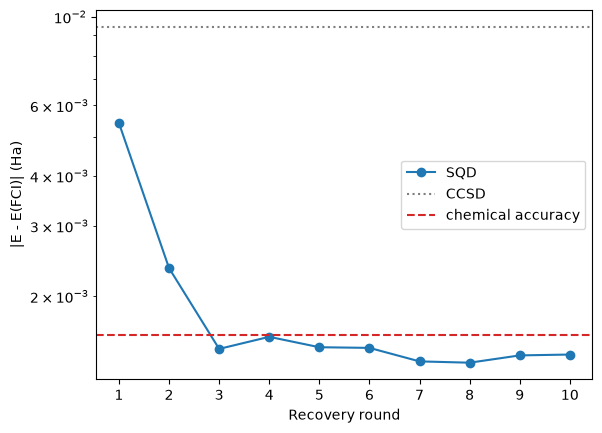

In [7]:
E_FCI = -109.10336546

rounds = range(1, len(round_energies) + 1)
plt.semilogy(
    rounds, np.abs(np.array(round_energies) - E_FCI), "o-", label="SQD"
)
plt.axhline(
    abs(ccsd.e_tot - E_FCI), color="tab:gray", linestyle=":", label="CCSD"
)
plt.axhline(
    1.6e-3, color="tab:red", linestyle="--", label="chemical accuracy"
)
plt.xlabel("Recovery round")
plt.ylabel("|E - E(FCI)| (Ha)")
plt.xticks(list(rounds))
plt.legend()
plt.show()

<Admonition type="note" title="How qcsc-prefect manages this step">

**Trace:** The task `sqd_loop` has the tag `post-process`. It receives the samples and
the integrals, so the graph shows two arrows into it. Each batch is one `FulqrumSolverJob`
call, a `solve_eigenstate` task that submits one Slurm job running Fulqrum. The batches of a round run concurrently
on the compute nodes. The `sqd-configuration-recovery` artifact lists the energy
and dimension of every subspace in every round.

**Configure:** The **SQD** group of the run form sets the subspace dimension, the number of batches, and the number of rounds. The solver is the **Solver Block** of the `sqd-advanced-settings` block, which `sqd-create-blocks` set to `fulqrum_solver_job/sqd-fulqrum-solver`. **Solver Block Override** (`solver_block_ref`) in the run form selects another block for one run, for example a DICE or SBD block. The eigensolver (PRIMME), threads, and walltime are in the `sqd-fulqrum-solver` block and its execution profile, not in the run form. The flow loads the solver block before any other stage, so a
wrong block name fails the run before it uses the QPU.

**Resume:** `sqd_loop` is not cached, but it saves a checkpoint after every round. The
checkpoint holds the occupancies that seed the next round and the best energy so far, in
`sqd_checkpoints/<flow run id>/ckpt_t00_w0.npz` under the solver's `work_dir`. On Retry, it
runs again from the stored samples and integrals, with the blocks as they are at that
time, and continues after the last completed round. Each solver job leaves a
`job_<timestamp>_<id>` directory under `work_dir` with its script, inputs, output, and
Slurm logs.

</Admonition>

> **Image placeholder** `docs/images/img-qcsc-prefect-step-postprocess.png`: **Trace** at HPC scale, with one task per solver job, running concurrently.
>
> *Capture proposal:* a crop of the flow run graph (timeline view) under `sqd_loop`, where each solver call is a `solve_eigenstate` task. The bars of one round overlap in time, and the rounds follow one another. This shows concurrent Slurm jobs tracked one by one.

### Summary of the stages

The task stages are outlined in the following image.

![The map stage runs the `compute_molecular_integrals` task. Its parameters are the molecule group, and integrals, amplitudes, and occupancies are stored in case they're needed for a retry. The optimize stage runs the `get_lucj_params` task. Its parameters are the circuit group, and LUCJ parameters are stored in case they're needed for a retry. The execute stage runs the `quantum_sampling` task. Its parameters are the sampling group and QRMI blocks, and samples (and their source as an artifact) are stored in case they're needed for a retry. The postprocess stage runs the `sqd_loop` task. Its parameters are the SQD group and solver blocks, and by default, a checkpoint is stored after every round in case they're needed for a retry.](/docs/images/tutorials/qcsc-prefect/task-graph.svg 'Task stages')

The parameters that you change between runs are in the run form, grouped by stage. The cluster
settings are in blocks, and the credentials are on the cluster. The expensive QPU result is
stored as soon as it exists.

## Run the full workflow

This section runs all four stages with one action in Prefect Cloud. The blocks from [Configure and create the Prefect blocks on the workflow host](#configure-and-create-the-prefect-blocks-on-the-workflow-host)
already describe the cluster and the QPU. A run needs only the run parameters.

### Submit the run

In Prefect Cloud, go to **Deployments**, select `sqd`, then select **Run** -> **Custom run**. Set the fields in the following table, keep the defaults for the others, and click **Submit**. Only the molecule has
no default. The form still marks the three SQD fields as required so that they stand out.

| Group | Field | Value |
|---|---|---|
| Molecule | FCIDump File | `~/qcsc-prefect/algorithms/open_loop/sqd/data/n2_631g_fc.fcidump` |
| Sampling | Quantum Source | `real-device` |
| Sampling | Shots | `100000` (the default) |
| Sampling | QRMI Runtime Block | `qrmi-runtime` (the default, from [Configure and create the Prefect blocks on the workflow host](#configure-and-create-the-prefect-blocks-on-the-workflow-host)) |
| SQD | Subspace Dimension | `1000000` (the default) |
| SQD | Batch Number | `4` (the default) |
| SQD | Max Iteration | `5` (the default) |
| SQD | Carryover Fraction | `0.5` (the default) |
| SQD | Checkpoint Recovery | On (the default) |
| &mdash; | Advanced Settings Block | `sqd-advanced-settings` (the default) |
| &mdash; | Solver Block Override | Empty (the default), which uses the solver block of `sqd-advanced-settings` |

A path relative to the qcsc-prefect checkout also works, because the flow resolves it
against the checkout. For scripted runs, the same parameters are in
`algorithms/open_loop/sqd/default_params/n2.json`.

**Checkpoint Recovery** is on by default and uses less than 1 MB of disk space per run, even
for 1000 orbitals. Each run adds one folder under `work_dir/sqd_checkpoints/`, and nothing
removes it.

> **Image placeholder** `docs/images/img-qcsc-prefect-submit.png`: the custom-run form of `sqd`, with the preceding values.
>
> *Capture proposal:* one tall screenshot of the form with the groups Molecule, Circuit, Sampling, and SQD expanded and the **Submit** button visible. Collapse the long Circuit group if the form does not fit, because the optimize step already shows it.

<Admonition type="note">

For a first run without the QPU, set **Quantum Source** to `random`. The flow uses uniform
random bitstrings, skips the optimize and execute stages, and still runs the solver jobs.
To sample from the workflow host through IBM Quantum Platform (IQP) instead of a Slurm job,
save a `QrmiRuntimeBlock` with
`scheduler = "iqp"` (the `[runtime]` table of the block config, in place of `[qrmi]`) and
name it in **QRMI Runtime Block**. It reads the API key from the workflow host's
`qrmi_config.json`.

</Admonition>

### Read the results

The flow run page shows everything about the run, which is the task graph and its states,
the logs, and the artifacts.

> **Image placeholder** `docs/images/img-qcsc-prefect-run.png`: the flow run page of a completed run, with the task graph of the four stages, the two arrows into `sqd_loop`, and the logs.
>
> *Capture proposal:* one full-window screenshot of the flow run page. The graph and the state of every task are at the top. Below them, open the **Logs** tab with the `quantum_sampling` lines that report the circuit compiled on the compute node, or the `sqd_loop` lines with the energy of each round. Expand `quantum_sampling` in the graph, if the UI allows it, so that `build_lucj_circuit` shows. Is this one screen readable at docs width, or should the logs be a second crop?

The run publishes four artifacts, which the **Artifacts** tab of the run lists.

| Artifact | Published by | Contents |
|---|---|---|
| `sqd-sampling-source` | Execute | Where the samples are (QRMI work directory, or IBM Quantum job ID for IQP), resource, and shots |
| `qrmi-slurm-job` | Execute | The ID, state, and work directory of the QRMI sampler's Slurm job |
| `sqd-configuration-recovery` | Postprocess | Energy and dimension of every subspace in every round |
| `sqd-checkpoint` | Postprocess | Checkpoint path, completed rounds, and best energy, when **Checkpoint Recovery** is on |

> **Image placeholder** `docs/images/img-qcsc-prefect-artifacts.png`: the artifacts of the run.
>
> *Capture proposal:* one composite figure. Left: the run's **Artifacts** tab listing the four artifacts. Right: the `sqd-configuration-recovery` table opened, with `sqd-sampling-source` below it if both fit. The artifacts have keys, so the top-level **Artifacts** page also lists their latest versions across runs, which could show all four in one screen instead. Which view reads better?

The energy reported by the flow is the lowest energy in the configuration-recovery table.
On the cluster, each solver job leaves a `job_<timestamp>_<id>` directory under `work_dir`,
with the rendered Slurm script, `input.npz`, `solver.json`, the Slurm output, and either
`output.npz` and `result.json`, or `error.json`. Use `sacct` to see the jobs of the run.

```bash
# Run in a terminal on the workflow host, not in this notebook.
sacct --format=JobID,JobName,State,ExitCode,Elapsed,WorkDir%60
```

## Optional: resume and reuse the workflow

### Retry a failed run, and reuse its samples

**Retry:** Suppose a solver job hits its walltime in round 4 of 5, and `sqd_loop` fails.
Raise the walltime in the `exec-sqd-fulqrum-slurm` block under **Blocks**, then click
**Retry** on the failed flow run. The retried run loads the stored results of the first
three stages, so it submits no QPU job. It runs only `sqd_loop` again, with the new
walltime, and starts at round 4 from the checkpoint of round 3. Its log shows
`[ckpt] RESUME from …: completed 3 step(s)`, then `SQD iteration 4/5`.

**Continue a recovery with more rounds:** The `sqd-checkpoint` artifact of a run gives the
path of its checkpoint. To continue that recovery in a new run, start a custom run with the
same parameters and the following changes.

- Set **Resume from Checkpoint** (`resume_checkpoint`) to that path.
- Raise **Max Iteration**.

The new run starts after the completed rounds, from the stored occupancies and best energy.
For example, if the checkpoint has 32 of 100 rounds done and the new run has
**Max Iteration** set to `200`, the new run continues at round 33/200.

The new run must use the same samples, molecule, **Subspace Dimension**, **Batch Number**,
and solver type (the `fulqrum_solver_job` part of the solver block) as the first run, so
reuse its samples as described in the next paragraph. The name and job settings of the
solver block, such as its walltime, can change. If anything else differs, the run fails
before any solver job and names the difference. The new run only reads the given
checkpoint and writes its own.

**Reuse:** A new run computes everything again unless you point it to earlier samples. To
try another subspace dimension with the same samples, start a custom run with the same parameters and the following changes.

- Set **Load from QRMI Job Directory** (`qrmi_result_dir`) to the work directory in the first run's
  `sqd-sampling-source` artifact.
- Change **Subspace Dimension**.

The execute stage of the new run is the task `load_qrmi_result`, which reads the samples and
submits nothing to the QPU. For samples taken through IQP, set
**Load from Qiskit Runtime Job ID** (`qiskit_runtime_job_id`) instead, and the stage is
`load_runtime_job`. This reload reads the job with the credentials of a prefect-qiskit
`QuantumRuntime` block, named in **Quantum Runtime Block (reload)** (`ibm-runner` by
default), which you create one time with `prefect block create quantum-runtime`.

> **Image placeholder** `docs/images/img-qcsc-prefect-retry-reuse.png`: a retried run, and a run that reuses samples.
>
> *Capture proposal:* one image with two graphs side by side. Left: the graph of a retried run, where the first three tasks completed from stored results and only `sqd_loop` ran again, with its `[ckpt] RESUME` log line. Right: the graph of a reuse run, with `load_qrmi_result` in place of `get_lucj_params` and `quantum_sampling`. Alternatively, the **Runs** list filtered to this deployment shows the original, retried, and reuse runs together with their states and durations. Would that single list be clearer than the two graphs?

## Next steps

<Admonition type="tip" title="Recommendations">

If you found this work interesting, you might be interested in the following material:

- [Sample-based quantum diagonalization of a chemistry Hamiltonian](/docs/tutorials/sample-based-quantum-diagonalization).
- [Run quantum workloads with QRMI](/docs/tutorials/run-quantum-workloads-with-qrmi).
- [Prefect concepts](https://docs.prefect.io/v3/concepts), such as flows, tasks, blocks, and deployments.
- [`qiskit-addon-sqd` documentation](/docs/addons/qiskit-addon-sqd).
- [QRMI](https://github.com/qiskit-community/qrmi) and
  [Fulqrum](https://github.com/Qiskit/qiskit-fulqrum).
- [QRMI Slurm sampler](https://qiskit-community.github.io/qcsc-prefect/howto/howto_qrmi_slurm_sampler/) and
  [Fulqrum integration](https://qiskit-community.github.io/qcsc-prefect/howto/howto_use_fulqrum_prefect/).
- [The SQD workflow source](https://github.com/qiskit-community/qcsc-prefect/tree/main/algorithms/open_loop/sqd).

</Admonition>

## References

[1] Robledo-Moreno, J., Motta, M., Haas, H., Javadi-Abhari, A., Jurcevic, P., Kirby, W., et al. (2025). Chemistry beyond the scale of exact diagonalization on a quantum-centric supercomputer. Science Advances, 11(25), eadu9991. [DOI](https://doi.org/10.1126/sciadv.adu9991), [arXiv:2405.05068](https://arxiv.org/abs/2405.05068)

[2] Kumar, K., Shirakawa, T., Kim, B., Wakizaka, R., Hamamura, I., Sato, M., et al. (2026). Broken-symmetry reference states for sample-based quantum diagonalization with near-DMRG accuracy. [arXiv:2611.04496](https://arxiv.org/abs/2611.04496)